Imports and data

In [1]:
import sys
sys.path.insert(0, "..")
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import torch

from src import io_utils, correct, correct_iterative as ci, fluence_utils, optical_props, colormap_inversion, train_v2

cfg = io_utils.load_config("dataset")
pinn_cfg = io_utils.load_config("pinn")
opt_cfg = io_utils.load_config("optical_props_750nm")
classes = cfg["classes"]
pixel_mm = cfg["pixel_mm"]
top_mm = cfg["image_top_depth_mm"]
max_gain = pinn_cfg["max_gain"]
cc = io_utils.load_config("correction")          # settings of the updated correction (notebook 09)

proc = io_utils.project_path("data", "processed", "x").parent
pred = io_utils.project_path("data", "predictions", "x").parent
class_maps = np.load(proc / "class_maps.npy")
dist = np.load(proc / "skin_distance_mm.npy")
pa_raw = np.load(proc / "pa_intensity.npy")          # the scanner image, scanner units
p0 = np.load(proc / "pa_denoised.npy")               # denoised, scanner units
us = np.load(proc / "us.npy")
info = json.load(open(proc / "preprocess_info.json"))
noise_sigma = float(np.mean(info["noise_sigma"]))
split = json.load(open(io_utils.project_path("data", "mc", "split.json")))
pool, test_frames, scale_01 = split["pool"], split["test_frames"], split["scale_01"]
flagged = json.load(open(proc / "crop_info.json"))["breathing_flagged_frames"]
physics = json.load(open(pred / "physics.json"))

n_frames, n_rows, n_cols = class_maps.shape
extent = [0, n_cols * pixel_mm, top_mm + n_rows * pixel_mm, top_mm]
x_mm = np.arange(n_cols) * pixel_mm
z_mm = top_mm + np.arange(n_rows) * pixel_mm
tissue = (class_maps > 0) & (dist > 0)

lut, _ = colormap_inversion.read_colorbar(io_utils.dataset_path(cfg, cfg["screen_capture"]), cfg["colorbar_column"],
                                          *cfg["colorbar_rows"], smooth=5)
pa1 = colormap_inversion.pa1_colormap(lut)

def load_baseline(name):
    """A precomputed baseline fluence map (1D exponential or 2D diffusion, saved on a 2x smaller grid) on the full grid, normalised to 1 under the skin."""
    baseline_scale = json.load(open(io_utils.project_path("v1_reference", "predictions", "physics.json")))["scale_01"]
    small = np.load(io_utils.project_path("v1_reference", "predictions", f"{name}.npy"))
    full = correct.upsample_fluence(small * baseline_scale, (n_rows, n_cols))
    return np.stack([fluence_utils.normalise_fluence(full[f], dist[f]) for f in range(n_frames)]).astype(np.float32)

fluence = {
    "No correction": np.ones_like(p0),
    "1D exponential": load_baseline("phi_1d"),
    "2D diffusion": load_baseline("phi_base_2d"),
    "Monte Carlo": np.load(io_utils.project_path("data", "mc", "fluence_mc.npy")),
}
MAIN = "PI-FluenceNet (literature α)"          # the final model

predict the fluence

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
pinn_cfg["tau_sigma_mm"], pinn_cfg["tau_scale_start"] = physics["tau_sigma_mm"], physics["tau_scale_start"]
checkpoint = io_utils.project_path("results", "checkpoints", f"{physics['main_name']}.pt")
model = train_v2.make_model(cfg, pinn_cfg, None, device)
model.load_state_dict(torch.load(checkpoint, map_location=device))
maps = {k: np.load(io_utils.project_path("data", "optical_maps", f"{k}.npy")) for k in ["mua", "musp", "mus", "g", "n"]}
data = train_v2.build_data(maps, class_maps, dist, np.zeros(p0.shape, np.float32), p0, cfg, pinn_cfg, pa_raw)
fluence[MAIN] = np.exp(train_v2.predict(model, data, list(range(n_frames)), device, literature=True)).astype(np.float32)
del data, maps
np.save(pred / "phi_pinn_literature.npy", fluence[MAIN])

saved = np.load(pred / "phi_pinn_forward.npy", mmap_mode="r")
diff = np.abs(np.log(np.maximum(fluence[MAIN], 1e-6)) - np.log(np.maximum(saved, 1e-6)))[tissue]
print(f"Model: {checkpoint.name} on {device}")
print(f"Fluence in tissue: {fluence[MAIN][tissue].min():.4f} - {fluence[MAIN][tissue].max():.2f}")
print(f"Against the predictions saved in notebook 05: |log ratio| median {np.median(diff):.5f}, 99th percentile {np.percentile(diff, 99):.4f}")

C:\Users\visha\AppData\Local\Temp\ipykernel_24796\3312598194.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint, map_location=de

Model: ensemble_seed4.pt on cuda
Fluence in tissue: 0.0003 - 2.58


Against the predictions saved in notebook 05: |log ratio| median 0.00083, 99th percentile 0.0023


## 2. Display compression γ
γ = (decay rate of the fluence) / (decay rate of the displayed PA) inside the kidney of the training frames, with the literature Monte Carlo fluence. It only works if the displayed PA decays with depth; in this dataset the kidney PA **rises** with depth (the bright band in the lower cortex, notebook 01), so the estimate is negative and the sample-dataset value is used.

In [3]:
kidney = [classes["cortex"], classes["medulla"]]
gamma_table = pd.DataFrame([{"depth window (mm)": f"{a}–{b}",
                             "gamma": correct.estimate_display_gamma(p0, fluence["Monte Carlo"], class_maps, dist, pool[::3], kidney, a, b)}
                            for a, b in [(1.5, 7.0), (2.0, 6.5), (2.0, 7.0), (2.5, 7.0), (2.0, 7.5)]])
gamma = cfg["display_gamma_fallback"] if (gamma_table["gamma"] <= 0).any() else float(gamma_table["gamma"].iloc[2])
gamma_table.to_csv(io_utils.project_path("results", "tables", "06_display_gamma.csv"), index=False)
print(gamma_table.round(2).to_string(index=False))
print(f"\nDisplay compression used: gamma = {gamma:.2f}")
source = "sample dataset (cannot be measured here)" if gamma == cfg["display_gamma_fallback"] else "this dataset"
json.dump({"gamma": gamma, "source": source}, open(pred / "display.json", "w"))

depth window (mm)  gamma
          1.5–7.0  -1.47
          2.0–6.5  -1.09
          2.0–7.0  -1.16
          2.5–7.0  -1.16
          2.0–7.5  -1.34

Display compression used: gamma = 3.02


PA correct every frame (whole image)

In [4]:
corrected, gains, excess = {}, {}, {}
for name, phi in fluence.items():
    frames_out = [ci.updated_correction(p0[f], phi[f], tissue[f], pa_raw[f] > 0, dist[f], gamma, cc, pixel_mm) for f in range(n_frames)]
    corrected[name] = np.stack([x for x, _, _ in frames_out]).astype(np.float32)
    gains[name] = np.stack([gn for _, gn, _ in frames_out]).astype(np.float32)
    excess[name] = np.stack([e for _, _, e in frames_out]).astype(np.float32)
    print(f"{name}: done")

g = gains[MAIN]
print(f"Gain of the PI-FluenceNet correction in tissue: median {np.median(g[tissue]):.2f}x, 99th percentile {np.percentile(g[tissue], 99):.2f}x, max {g[tissue].max():.2f}x (limit {max_gain:.0f}x)")
print(f"Tissue pixels where the gain is limited (> 90 % of the limit): {100 * (g[tissue] > 0.9 * max_gain).mean():.2f} %")
print(f"Tissue pixels blanked to 0 by the correction: {100 * ((corrected[MAIN] == 0) & (pa_raw > 0) & tissue).mean():.3f} %  (only pixels that were already 0 stay 0)")
print(f"Corrected tissue pixels above the scanner's display range (> 1): {100 * (corrected[MAIN][tissue] > 1).mean():.2f} %")
print(f"Tissue pixels pulled down by the depth limit (E > 1): {100 * (excess[MAIN][tissue] > 1).mean():.1f} %, largest E {excess[MAIN][tissue].max():.2f}")
np.save(pred / "pa_corrected_v2.npy", corrected[MAIN])
np.save(pred / "gain_v2.npy", g)

No correction: done


1D exponential: done


2D diffusion: done


Monte Carlo: done


PI-FluenceNet (literature α): done


Gain of the PI-FluenceNet correction in tissue: median 4.15x, 99th percentile 9.06x, max 9.63x (limit 10x)
Tissue pixels where the gain is limited (> 90 % of the limit): 1.35 %


Tissue pixels blanked to 0 by the correction: 0.000 %  (only pixels that were already 0 stay 0)
Corrected tissue pixels above the scanner's display range (> 1): 0.00 %


Tissue pixels pulled down by the depth limit (E > 1): 78.9 %, largest E 4.01


All methods(1D, 2D, MC, PI_FluenceNet)

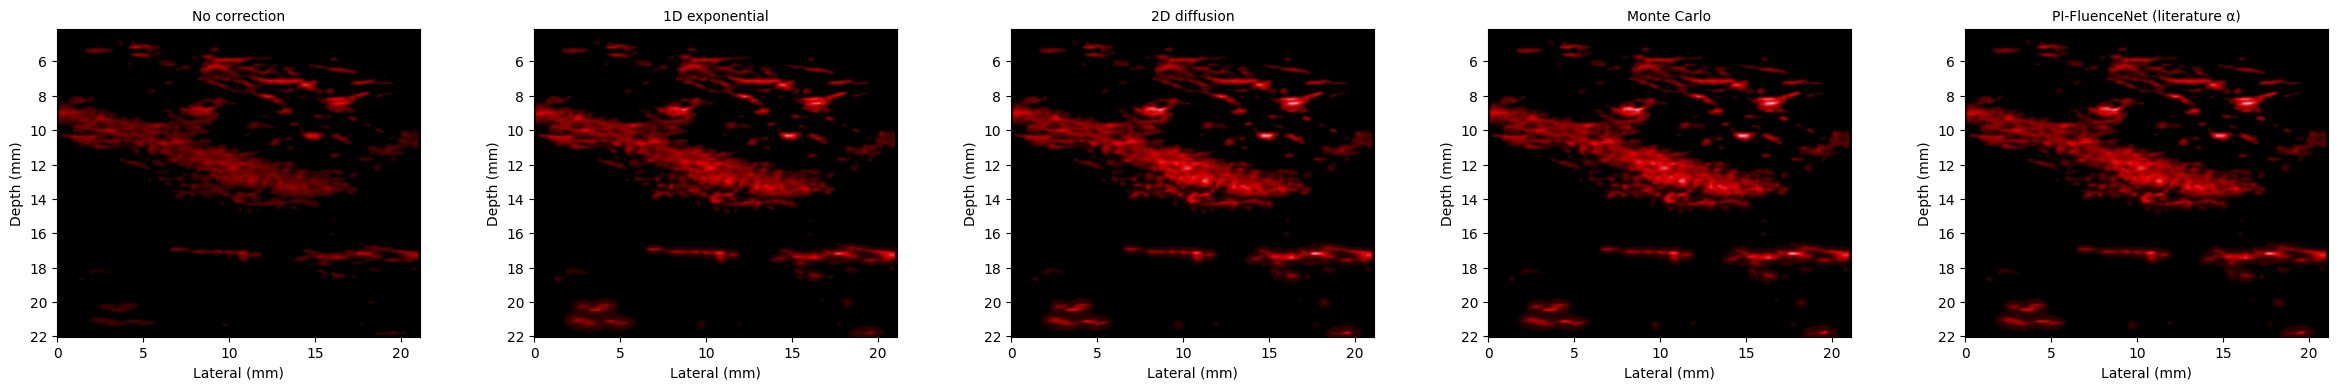

In [5]:
def show(ax, img, title, cmap=pa1, vmin=0, vmax=1, colorbar=True):
    im = ax.imshow(img, cmap=cmap, extent=extent, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Lateral (mm)")
    ax.set_ylabel("Depth (mm)")
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.035)
    return im

f = test_frames[0]
fig, axes = plt.subplots(1, len(corrected), figsize=(4.8 * len(corrected), 3.8))
for ax, (name, img) in zip(axes, corrected.items()):
    show(ax, pa_raw[f] if name == "No correction" else img[f], name, colorbar=False)
plt.tight_layout()
io_utils.save_figure(fig, "06_methods_side_by_side")
plt.show()

Signal vs depth

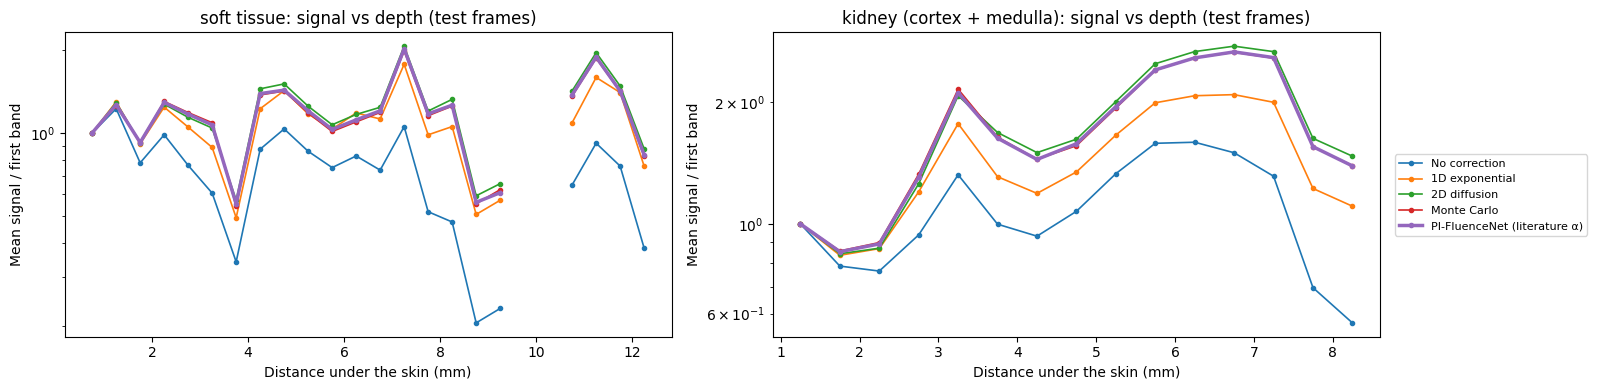

In [6]:
bins = np.arange(0.0, 12.5, 0.5)

def depth_curve(images, rule):
    curves = np.full((len(test_frames), len(bins)), np.nan)
    for i, f in enumerate(test_frames):
        roi = rule(f) & (pa_raw[f] > 0)          # pixels the scanner shows (not black)
        for j, b in enumerate(bins):
            sel = roi & (dist[f] >= b) & (dist[f] < b + 0.5)
            if sel.sum() > 120:
                curves[i, j] = images[f][sel].mean()
    has = np.isfinite(curves).any(axis=0)
    mean = np.full(len(bins), np.nan)
    mean[has] = np.nanmean(curves[:, has], axis=0)
    return mean

rules = {"soft tissue": lambda f: class_maps[f] == classes["soft_tissue"],
         "kidney (cortex + medulla)": lambda f: np.isin(class_maps[f], kidney)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (rname, rule) in zip(axes, rules.items()):
    for name, img in corrected.items():
        curve = depth_curve(img, rule)
        ref = curve[np.isfinite(curve)][0]
        ax.plot(bins + 0.25, curve / ref, "o-", ms=3, label=name, lw=2.5 if name.startswith("PI-FluenceNet") else 1.2)
    ax.set_yscale("log")
    ax.set_xlabel("Distance under the skin (mm)")
    ax.set_ylabel("Mean signal / first band")
    ax.set_title(f"{rname}: signal vs depth (test frames)")
handles, labels = axes[0].get_legend_handles_labels()
plt.tight_layout()
fig.legend(handles, labels, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5), borderaxespad=0)
io_utils.save_figure(fig, "06_depth_profiles")
plt.show()

Region means before and after correction

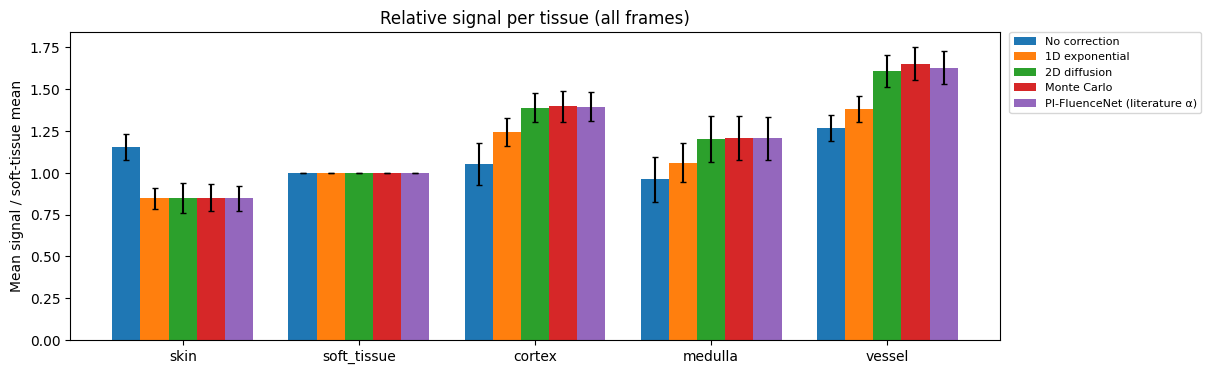

Literature mua ratio cortex/medulla: 1.46


region,skin,soft_tissue,cortex,medulla,vessel,cortex/medulla
method,,,,,,
1D exponential,0.847,1.0,1.244,1.060,1.381,1.174
2D diffusion,0.848,1.0,1.390,1.203,1.610,1.156
Monte Carlo,0.852,1.0,1.397,1.209,1.653,1.155
No correction,1.157,1.0,1.055,0.961,1.266,1.098
PI-FluenceNet (literature α),0.848,1.0,1.397,1.206,1.629,1.158


In [7]:
region_names = ["skin", "soft_tissue", "cortex", "medulla", "vessel"]
region_mask = tissue & (dist <= pinn_cfg["pa_max_depth_mm"]) & (pa_raw > 0)      # pixels the scanner shows
rows = []
for name, img in corrected.items():
    per_frame = pd.DataFrame([correct.region_means(img[f], class_maps[f], {k: classes[k] for k in region_names}, region_mask[f])
                              for f in range(n_frames)])
    per_frame = per_frame.div(per_frame["soft_tissue"], axis=0)
    for r in region_names:
        rows.append({"method": name, "region": r, "mean": per_frame[r].mean(), "std": per_frame[r].std()})
region_df = pd.DataFrame(rows)
region_df.to_csv(io_utils.project_path("results", "tables", "06_region_means.csv"), index=False)

fig, ax = plt.subplots(figsize=(12, 4))
width = 0.8 / len(corrected)
for i, name in enumerate(corrected):
    d = region_df[region_df["method"] == name].set_index("region").loc[region_names]
    ax.bar(np.arange(len(region_names)) + (i - (len(corrected) - 1) / 2) * width, d["mean"], width, yerr=d["std"], capsize=2, label=name)
ax.set_xticks(np.arange(len(region_names)), region_names)
ax.set_ylabel("Mean signal / soft-tissue mean")
ax.set_title("Relative signal per tissue (all frames)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
io_utils.save_figure(fig, "06_region_means")
plt.show()
table = region_df.pivot(index="method", columns="region", values="mean")[region_names]
table["cortex/medulla"] = table["cortex"] / table["medulla"]
props = optical_props.class_properties(opt_cfg)
print(f"Literature mua ratio cortex/medulla: {props['cortex']['mua'] / props['medulla']['mua']:.2f}")
table.round(3)

Frame stability

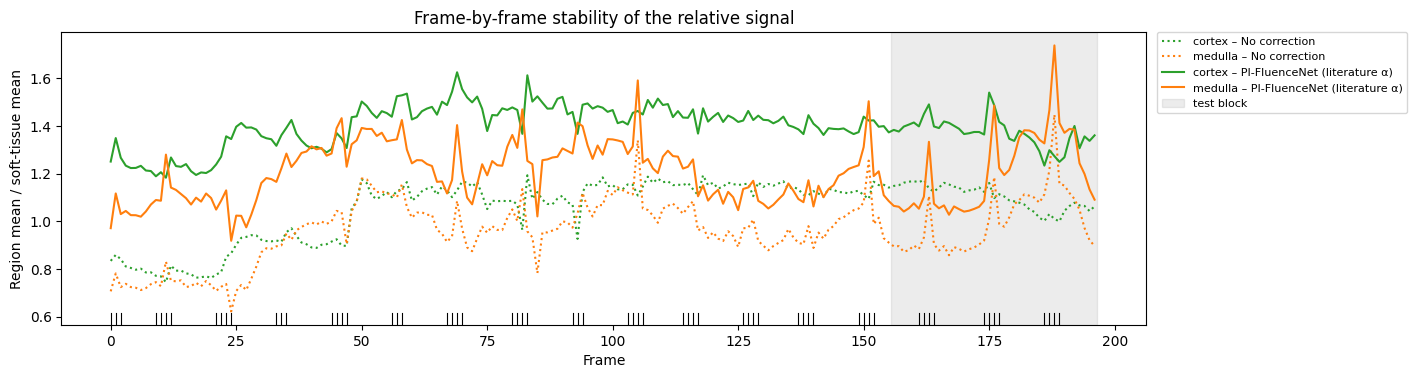

In [8]:
fig, ax = plt.subplots(figsize=(14, 3.8))
for name, ls in [("No correction", ":"), (MAIN, "-")]:
    for r, colour in [("cortex", "tab:green"), ("medulla", "tab:orange")]:
        vals = [corrected[name][f][region_mask[f] & (class_maps[f] == classes[r])].mean() /
                corrected[name][f][region_mask[f] & (class_maps[f] == classes["soft_tissue"])].mean() for f in range(n_frames)]
        ax.plot(range(n_frames), vals, ls, color=colour, label=f"{r} – {name}")
ax.axvspan(test_frames[0] - 0.5, test_frames[-1] + 0.5, color="grey", alpha=0.15, label="test block")
for fb in flagged:
    ax.axvline(fb, ymax=0.04, color="k", lw=0.8)
ax.set_xlabel("Frame")
ax.set_ylabel("Region mean / soft-tissue mean")
ax.set_title("Frame-by-frame stability of the relative signal")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
io_utils.save_figure(fig, "06_frame_stability")
plt.show()

## Relative absorption map 

In [9]:
props = optical_props.class_properties(opt_cfg)
tissue_names = ["skin", "soft_tissue", "cortex", "medulla", "vessel"]
literature_rel = {t: 100 * props[t]["mua"] / props["vessel"]["mua"] for t in tissue_names}

def relative_maps(images):
    return np.stack([ci.relative_absorption(images[f], tissue[f], pa_raw[f] > 0, dist[f], gamma, cc["rel_reference_percentile"],
                                            cc["rel_reference_depth_mm"])[0] for f in range(n_frames)]).astype(np.float32)

rel_maps = {"Uncorrected": relative_maps(p0), "Corrected": relative_maps(corrected[MAIN])}
np.save(pred / "relative_absorption_literature.npy", rel_maps["Corrected"])

def region_values(maps):
    """Mean relative absorption of the visible pixels of each tissue (down to 14 mm), one row per frame."""
    rows = []
    for f in range(n_frames):
        row = {}
        for t in tissue_names:
            sel = (class_maps[f] == classes[t]) & (pa_raw[f] > 0) & tissue[f] & (dist[f] <= 14)
            row[t] = maps[f][sel].mean() if sel.sum() >= 30 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

rel_rows = {}
for name, maps_ in rel_maps.items():
    v = region_values(maps_)
    for block, frames_ in [("all frames", range(n_frames)), ("test frames", test_frames)]:
        sub = v.loc[list(frames_)]
        error = 100 * np.mean([abs(sub[t].mean() - literature_rel[t]) / literature_rel[t] for t in tissue_names[:4]])
        rel_rows[f"{name}, {block}"] = {**{t: f"{sub[t].mean():.1f} ± {sub[t].std():.1f}" for t in tissue_names}, "mean |error| (%)": round(error, 1)}
rel_rows["literature"] = {**{t: round(literature_rel[t], 1) for t in tissue_names}, "mean |error| (%)": ""}
rel_table = pd.DataFrame(rel_rows).T
rel_table.to_csv(io_utils.project_path("results", "tables", "06_relative_absorption.csv"))
rel_table

,skin,soft_tissue,cortex,medulla,vessel,mean |error| (%)
"Uncorrected, all frames",7.6 ± 0.9,5.9 ± 0.7,4.7 ± 1.5,4.0 ± 1.5,12.1 ± 1.9,83.8
"Uncorrected, test frames",7.3 ± 0.6,6.2 ± 0.5,5.5 ± 0.5,4.7 ± 1.5,13.6 ± 1.2,80.0
"Corrected, all frames",2.6 ± 0.8,5.0 ± 0.5,8.8 ± 1.0,6.5 ± 1.7,17.1 ± 1.9,24.6
"Corrected, test frames",2.1 ± 0.3,5.1 ± 0.3,8.2 ± 0.8,6.4 ± 2.1,18.1 ± 1.4,30.0
literature,2.7,5.0,17.0,11.7,100.0,


### Relative absorption per tissue, frame by frame
Cortex, medulla and soft tissue of the corrected relative map over all 197 frames; the test block is shaded. The dotted lines are the literature values.

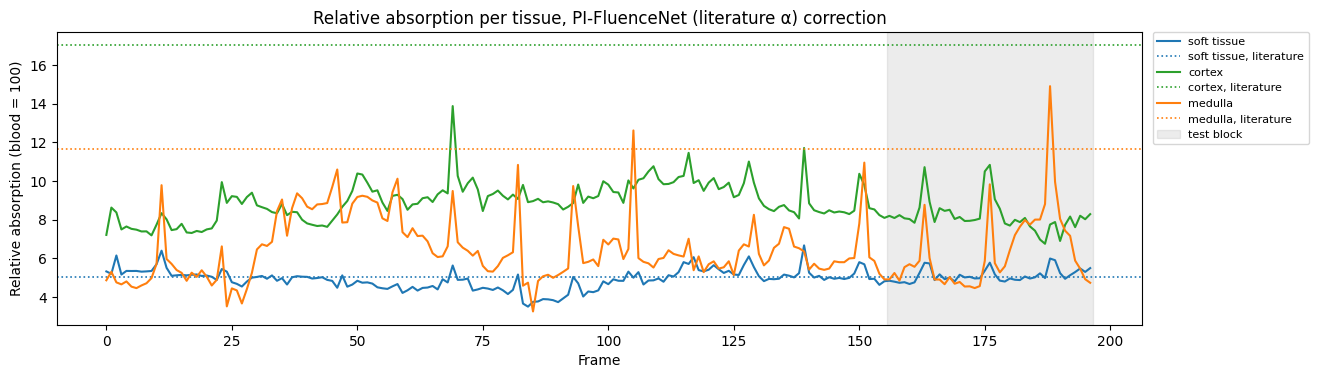

In [10]:
v = region_values(rel_maps["Corrected"])
fig, ax = plt.subplots(figsize=(14, 3.8))
for t, colour in [("soft_tissue", "tab:blue"), ("cortex", "tab:green"), ("medulla", "tab:orange")]:
    ax.plot(range(n_frames), v[t], color=colour, label=t.replace("_", " "))
    ax.axhline(literature_rel[t], color=colour, ls=":", lw=1.2, label=f"{t.replace('_', ' ')}, literature")
ax.axvspan(test_frames[0] - 0.5, test_frames[-1] + 0.5, color="grey", alpha=0.15, label="test block")
ax.set_xlabel("Frame")
ax.set_ylabel("Relative absorption (blood = 100)")
ax.set_title("Relative absorption per tissue, PI-FluenceNet (literature α) correction")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
io_utils.save_figure(fig, "06_relative_absorption_frames")
plt.show()